# Tech-Challenge 02
Desenvolver um modelo de classificação capaz de prever a qualidade de um vinho com base em suas características físicas-químicas. Para simplificar o problema, a variável de qualidade deverá ser transformada em uma classificação binária, por exemplo:
* Vinho de Alta Qualidade: nota ≥ 7
* Vinho de Baixa/Média Qualidade: nota < 7

O objetivo é treinar e avaliar modelos de aprendizado de máquina capazes de prever essa classificação a partir das variáveis disponíveis.

Fonte: [wine-quality-dataset](https://www.kaggle.com/datasets/yasserh/wine-quality-dataset)

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# upload do arquivo
df = pd.read_csv('WineQT.csv')

# conferindo as primeiras linhas
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [3]:
# dando umas corrigidas
# remover a coluna ID para nao atrapalhar
df = df.drop(columns=['Id'])

# traduzir os nomes das colunas para facil entendivmento
df = df.rename(columns={
    'fixed acidity': 'acidez_fixa',
    'volatile acidity': 'acidez_volatil',
    'citric acid': 'acido_citrico',
    'residual sugar': 'acucar_residual',
    'chlorides': 'cloretos',
    'free sulfur dioxide': 'dioxido_enxofre_livre',
    'total sulfur dioxide': 'dioxido_enxofre_total',
    'density': 'densidade',
    'pH': 'ph',
    'sulphates': 'sulfatos',
    'alcohol': 'alcool'
})

# conferindo as primeiras linhas com as correcoes
df.head()

,acidez_fixa,acidez_volatil,acido_citrico,acucar_residual,cloretos,dioxido_enxofre_livre,dioxido_enxofre_total,densidade,ph,sulfatos,alcool,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [4]:
# verificar se tem dados nulos na base
print("Valores nulos por coluna:")
print(df.isnull().sum())

Valores nulos por coluna:
acidez_fixa              0
acidez_volatil           0
acido_citrico            0
acucar_residual          0
cloretos                 0
dioxido_enxofre_livre    0
dioxido_enxofre_total    0
densidade                0
ph                       0
sulfatos                 0
alcool                   0
quality                  0
dtype: int64


# **Sem nulos**
Com isso concluimos que a base não possui nenhum valor nulo. Isso ajuda a eliminar a necessidade de descarte de registros.

In [5]:
# qualidade para binario
# alta qualidade (>= 7) = 1 | baixa/media qualidade (< 7) = 0
df['alvo_qualidade'] = (df['quality'] >= 7).astype(int)

# remover a coluna QUALITY para que o modelo nao tenha acesso a resposta original durante o treinamento, apenas o sistema binario
df = df.drop(columns=['quality'])

# exibir a porcentagem de vinhos de qualidade alta e baixa/media
print("Proporção das classes (0 = Qualidade Baixa/Média, 1 = Qualidade Alta):")
print(df['alvo_qualidade'].value_counts(normalize=True) * 100)

Proporção das classes (0 = Qualidade Baixa/Média, 1 = Qualidade Alta):
alvo_qualidade
0    86.089239
1    13.910761
Name: proportion, dtype: float64


# **Logo temos:**

*   *86,09%* de vinhos com qualidade baixa/média.
*   *13,91%* de vinhos com qualidade alta.

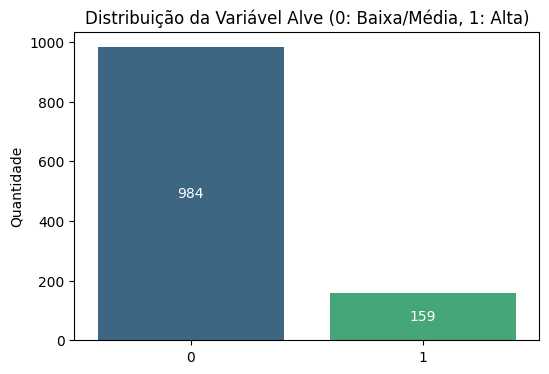

In [6]:
# Grafico 1: comparando a distribuicao da qualidade
plt.figure(figsize=(6,4))
ax = sns.countplot(data=df, x='alvo_qualidade', hue='alvo_qualidade', palette='viridis', legend=False)
plt.title('Distribuição da Variável Alve (0: Baixa/Média, 1: Alta)')
for container in ax.containers:
  ax.bar_label(container, label_type='center', color='white')
plt.ylabel('Quantidade')
plt.xlabel('')
plt.show()

**Gráfico 1:** Produzir um vinho de alta qualidade é um processo difícil e caro, dependendo da safra, clima, fermentação e armazenamento. Na nossa base de dados a maioria dos vinhos são de qualidade baixa/média, e isso é um aviso, o nosso modelo ira ver muito mais exemplos de vinhos comuns do que excepcionais.

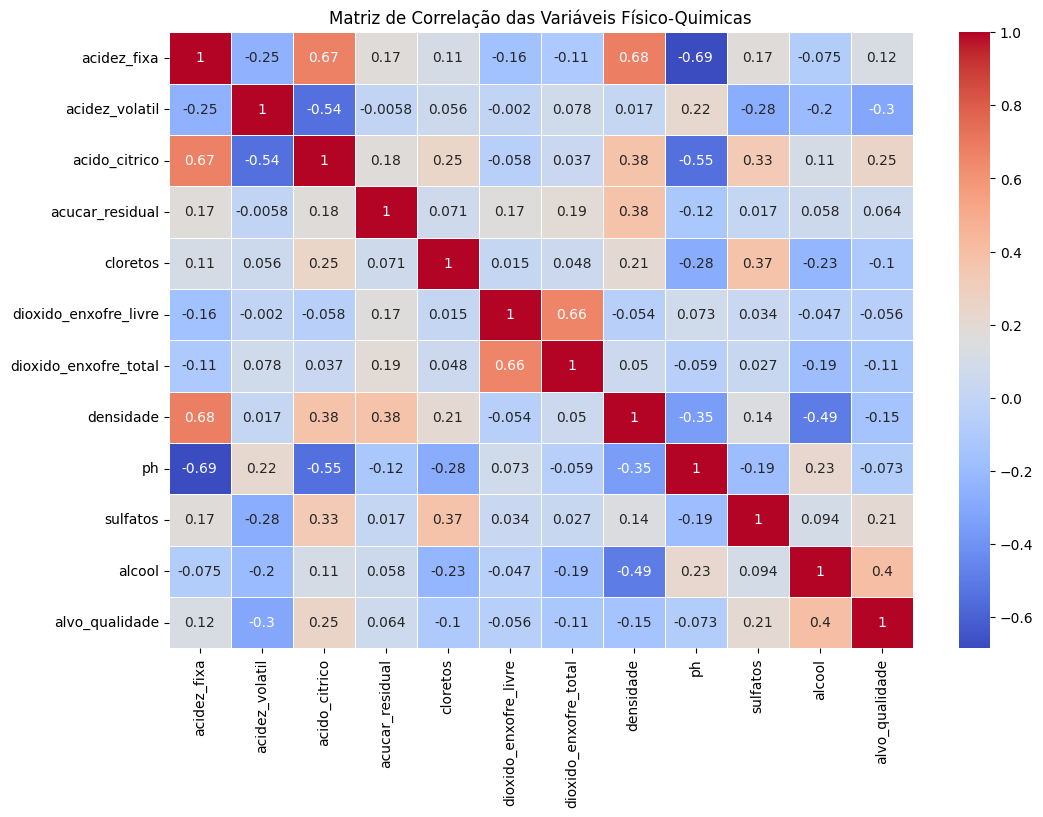

In [7]:
# Grafico 2: matriz de correlacao
plt.figure(figsize=(12,8))
correlacao_calc = df.corr()
sns.heatmap(correlacao_calc, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Matriz de Correlação das Variáveis Físico-Quimicas')
plt.show()

**Gráfico 2:** Aqui é mostrado o que "estraga" ou o o que "melhora" a nota do vinho de forma geral, podendo guiar quais varáveis os diretores das vinicolas devem monitorar mais de perto.

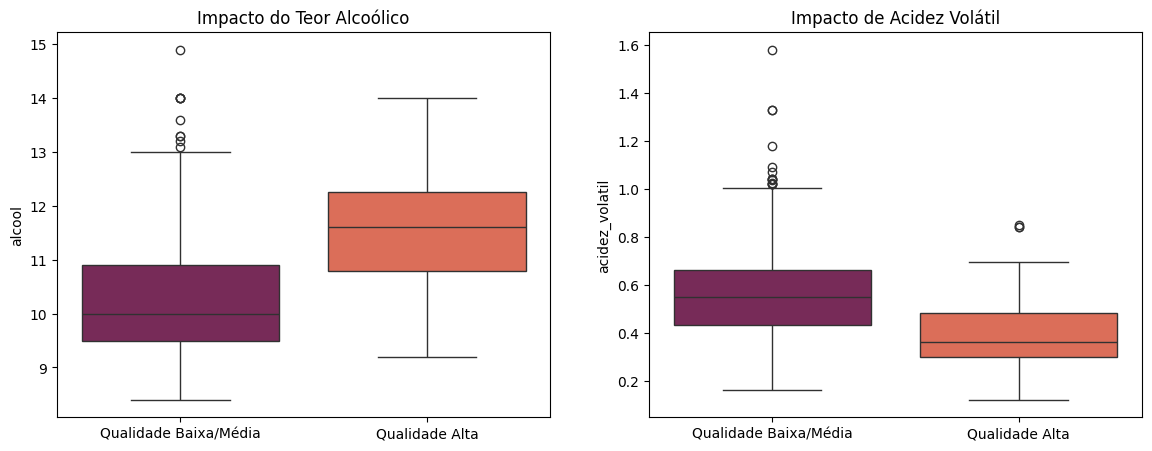

In [8]:
# Grafico 3: impacto de varaveis
fig, graficos = plt.subplots(1, 2, figsize=(14,5))
rotulos_x = ['Qualidade Baixa/Média', 'Qualidade Alta']

sns.boxplot(data=df, x='alvo_qualidade', y='alcool', ax=graficos[0], hue='alvo_qualidade', palette='rocket', legend=False )
graficos[0].set_title('Impacto do Teor Alcoólico')
graficos[0].set_xticks([0,1])
graficos[0].set_xticklabels(rotulos_x)
graficos[0].set_xlabel('')

sns.boxplot(data=df, x='alvo_qualidade', y='acidez_volatil', ax=graficos[1], hue='alvo_qualidade', palette='rocket', legend=False)
graficos[1].set_title('Impacto de Acidez Volátil')
graficos[1].set_xticks([0,1])
graficos[1].set_xticklabels(rotulos_x)
graficos[1].set_xlabel('')

plt.show()

**Gráfico 3:**


*   **Impacto do Teor Alcoólico:** O álcool é responsável por dar o "corpo" da
bebida, para dar aquela sensação de volume e textura na boca. Vinhos com pouco álcool podem aparecer "aguados" para os especiliastas, por isso teores mais altos tendem a receber notas melhores.
*   **Impacto de Acidez Volátil:** A acidez volátil mede, basicamente a quantidade e ácido acético na bebida. Em níveis altos, o vinho fica com cheiro e gosto de vinagre, indicando que bactérias indesejadas agiram durante a fermentação. É um defeito grave, por isso derruba a nota imediatamente.







# Outliers?
Pelos gráficos, podemos ver que surgiram alguns outliers (valores um pouco fora do padrão) nos dados. No mundo dos vinhos, esses números diferentes quase nunca são erros de digitação ou falha de equipamento; eles costumam representar características reais de algumas safras específicas ou de estilos de vinhos diferentes. Alem disso, os mdoelos escolhidos conseguem lidar bem com esses outliers, então não tem necessidade de jogar a informação fora.

In [9]:
# preparando os dados
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# separador de tabela
X = df.drop(columns=['alvo_qualidade'])
y = df['alvo_qualidade']

# treino e teste
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# padronizacao de escala
padronizador = StandardScaler()
X_treino_padronizado = padronizador.fit_transform(X_treino)
X_teste_padronizado = padronizador.transform(X_teste)

In [10]:
# treinamento dos modelos
from sklearn.ensemble import RandomForestClassifier as rfc
from xgboost import XGBClassifier as xgbc

# modelo 1: random florest
florest = rfc(n_estimators=100, class_weight='balanced', random_state=42)
florest.fit(X_treino_padronizado, y_treino)

# modelo 2: XGBoost
peso_compensacao = y_treino.value_counts()[0] / y_treino.value_counts()[1]
xgboost = xgbc(eval_metric='logloss', scale_pos_weight=peso_compensacao, random_state=42)
xgboost.fit(X_treino_padronizado, y_treino)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...)

---Avaliação do Modelo: Random Florest---
              precision    recall  f1-score   support

           0       0.91      0.96      0.93       295
           1       0.59      0.40      0.47        48

    accuracy                           0.88       343
   macro avg       0.75      0.68      0.70       343
weighted avg       0.86      0.88      0.87       343

Nota ROC-AUC (capacidade de separar bons e ruins): 0.8592



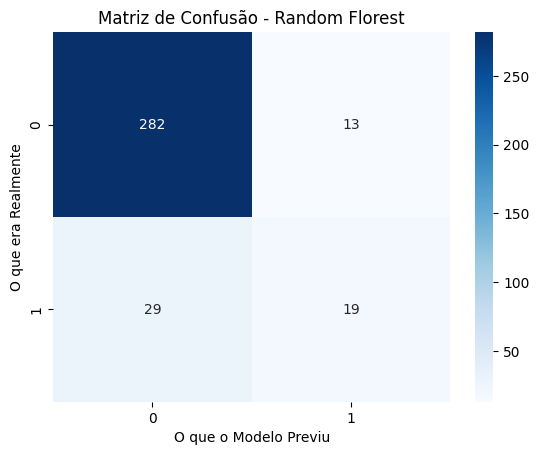

---Avaliação do Modelo: XGBoost---
              precision    recall  f1-score   support

           0       0.93      0.91      0.92       295
           1       0.49      0.56      0.52        48

    accuracy                           0.86       343
   macro avg       0.71      0.73      0.72       343
weighted avg       0.87      0.86      0.86       343

Nota ROC-AUC (capacidade de separar bons e ruins): 0.8230



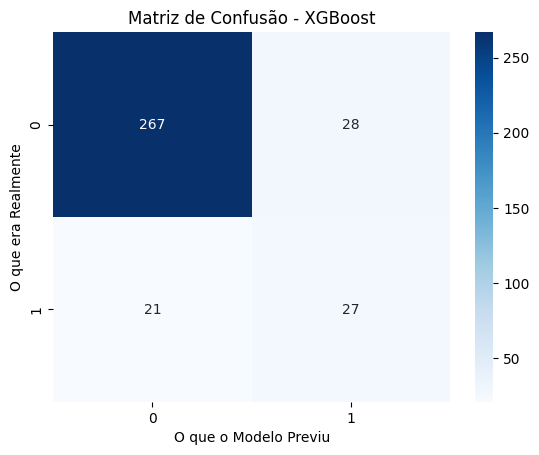

In [11]:
# avaliacao dos modelos
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# criando a funcao para avaliacao
def avaliar_modelo(modelo_treinado, nome_modelo):
  previsoes = modelo_treinado.predict(X_teste_padronizado)
  probabilidades = modelo_treinado.predict_proba(X_teste_padronizado)[:,1]

  print(f"---Avaliação do Modelo: {nome_modelo}---")
  print(classification_report(y_teste, previsoes))
  print(f"Nota ROC-AUC (capacidade de separar bons e ruins): {roc_auc_score(y_teste, probabilidades):.4f}\n")

  matriz = confusion_matrix(y_teste, previsoes)
  sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues')
  plt.title(f'Matriz de Confusão - {nome_modelo}')
  plt.xlabel('O que o Modelo Previu')
  plt.ylabel('O que era Realmente')
  plt.show()

avaliar_modelo(florest, "Random Florest")
avaliar_modelo(xgboost, "XGBoost")

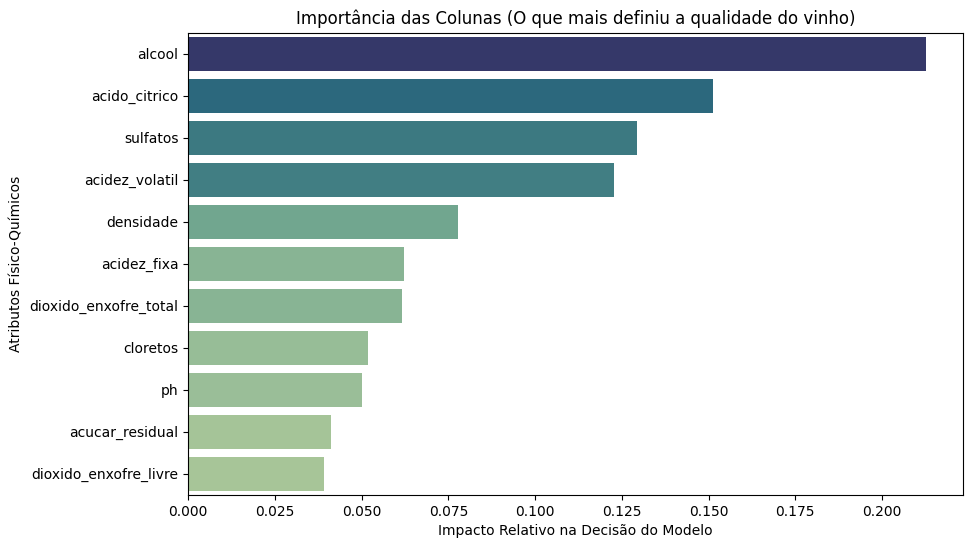

In [12]:
# extracao de insights
importancia_das_colunas = pd.Series(
    florest.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=importancia_das_colunas.values, y=importancia_das_colunas.index, hue=importancia_das_colunas, palette='crest', legend=False)
plt.title('Importância das Colunas (O que mais definiu a qualidade do vinho)')
plt.xlabel('Impacto Relativo na Decisão do Modelo')
plt.ylabel('Atributos Físico-Químicos')
plt.show()

In [13]:
from sklearn.metrics import precision_score, recall_score, roc_auc_score

# extracao de previsao e certeza de cada modelo
previsoes_floresta = florest.predict(X_teste_padronizado)
prob_floresta = florest.predict_proba(X_teste_padronizado)[:,1]

previsoes_xgb = xgboost.predict(X_teste_padronizado)
prob_xgb = xgboost.predict_proba(X_teste_padronizado)[:,1]

# criacao da tabela de comparacao
quadro_resultado = pd.DataFrame({
    'Métrica de Avaliação': [
        'Precição (Acertos ao rotular Premium)',
        'Recall (Capacidade de encontrar Premium)',
        'ROC-AUC (Poder geral de separação)'
    ],
    'Random Forest': [
        precision_score(y_teste, previsoes_floresta),
        recall_score(y_teste, previsoes_floresta),
        roc_auc_score(y_teste, prob_floresta)
    ],
    'XGBoost': [
        precision_score(y_teste, previsoes_xgb),
        recall_score(y_teste, previsoes_xgb),
        roc_auc_score(y_teste, prob_xgb)
    ]
})

# mostrar a tabela
print("RESULTADO: Random Forest vs XGBoost---")
print(quadro_resultado.to_string(index=False, float_format=lambda x:f"{x:.2%}"))

RESULTADO: Random Forest vs XGBoost---
                    Métrica de Avaliação  Random Forest  XGBoost
   Precição (Acertos ao rotular Premium)         59.38%   49.09%
Recall (Capacidade de encontrar Premium)         39.58%   56.25%
      ROC-AUC (Poder geral de separação)         85.92%   82.30%


Com este quadro podemos perceber 3 coisas:
*   o que tem a maior Precisão (*Random Forest*) é o modelo mais rigoroso, quando a qualidade do vinho é alta, ele raramente se engana.
*   o que tem o maior Recall (*XGBoost*) é o que deixa escapar menos vinhos de qualidade alta.
*   o que tem o maior ROC-AC (*Random Forest*) é o vencedor técnico, o que conseguiu separar mais vinhos de qualidade alta.



# O que os resultados significam para o negócio?
Como podemos ver, o que mais importou para modelo, foram o Teor Alcoólico e a Acidez Volátil que são pontos principais para definir se um vinho sera bom ou não.
* O que se pode fazer na produção é dar uma atenção a mais na etapa de fermentação, para que garanta um teor alcoólico equilibrado para que dê "corpo" ao vinho.

* Os dois modelos se sairam bem para identificar os vinhos de qualidade comum. O XGBoost foi melhor na hora de encontrar os vinhos de qualidade alta, apesar de termos poucos vinhos com esse nivel ainda dificulta o aprendizado. A conclusão é que o modelo já pode ser usado no dia a dia como uma triagem rápida na produção, mas ficara melhor ainda no futuro conforme formos alimentando o sistema com mais vinhos de alta qualidade.

# Referência:

* Como é a produção de vinho? Entenda as etapas da vinificação - https://www.divvino.com.br/blog/producao-de-vinhos/?srsltid=AYCX9vIPAysEppHRo9vJqvMzufJpxcxdKhoyJWDIxdsmxG-92vDcE_WC


* Como saber se o vinho é de boa qualidade? - https://www.divvino.com.br/blog/vinho-de-boa-qualidade/?srsltid=AYCX9vK1_F8oCWmmEDHheOgtVLk_tYafGoSCku31ECVEbHsUtrknWrtg